# FaceUnlock: face verification CNN

Pipeline: data setup, EDA, preprocessing, model training, evaluation.

Runs on a Mac (cheap cells, local data) and on Google Colab (training, data from Kaggle).

## 0a. Colab bootstrap

On Colab only: clone the repo (or pull the latest code if it is already cloned) so `src/` is available, then work from its `notebook/` folder so relative paths match a local run. This is the one cell that must run before the imports.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/hycienti/ml-pipeline-faceunlock.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if Path("../src").exists():  # re-running in the same session: get the latest code
        subprocess.run(["git", "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", REPO_URL], check=True)
        os.chdir("ml-pipeline-faceunlock/notebook")

sys.path.insert(0, str(Path("..").resolve()))

## 0b. Imports

All other libraries used in the notebook are imported here, once.

In [2]:
import json
import random
import warnings
from pathlib import Path

# Set before third-party imports: some warn while importing.
warnings.filterwarnings("ignore")

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from src.preprocessing import build_pairs, center_crop, detect_and_crop, resize_face
from src.evaluation import embed_faces, evaluate_pairs, pair_scores
from src.preprocessing import scale_pixels
from src.training import RunConfig, train

## 1. Setup and data location

`IN_COLAB` is `True` only on Colab. On Colab we download LFW (Labeled Faces in the Wild) from Kaggle; locally we use the copy in `data/lfw`.

In [3]:
if IN_COLAB:
    LFW_ROOT = Path(kagglehub.dataset_download("jessicali9530/lfw-dataset"))
else:
    LFW_ROOT = Path("../data/lfw")

FACES_DIR = LFW_ROOT / "lfw-deepfunneled" / "lfw-deepfunneled"
print(FACES_DIR, "exists:", FACES_DIR.exists())

Using Colab cache for faster access to the 'lfw-dataset' dataset.
/kaggle/input/lfw-dataset/lfw-deepfunneled/lfw-deepfunneled exists: True


## 2. EDA: photos per person (LFW)

Face verification needs several photos of the same person. This shows how many people have enough.

count    5749.000000
mean        2.301792
std         9.016410
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max       530.000000
dtype: float64
George_W_Bush        530
Colin_Powell         236
Tony_Blair           144
Donald_Rumsfeld      121
Gerhard_Schroeder    109
Ariel_Sharon          77
Hugo_Chavez           71
Junichiro_Koizumi     60
Jean_Chretien         55
John_Ashcroft         53
dtype: int64
People with 2+ photos: 1680


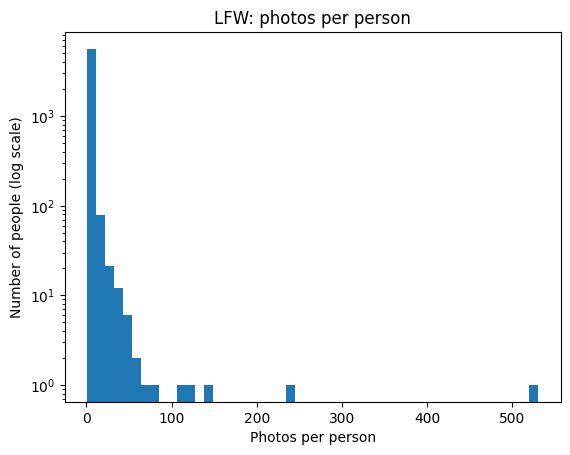

In [4]:
counts = pd.Series(
    {p.name: len(list(p.glob("*.jpg"))) for p in FACES_DIR.iterdir() if p.is_dir()}
).sort_values(ascending=False)

print(counts.describe())
print(counts.head(10))
print("People with 2+ photos:", (counts >= 2).sum())

counts.plot(kind="hist", bins=50, log=True)
plt.xlabel("Photos per person")
plt.ylabel("Number of people (log scale)")
plt.title("LFW: photos per person")
plt.show()

## 3. EDA: sample LFW faces

Two photos each of eight random people (one column per person), plus the size and colour mode of a photo.

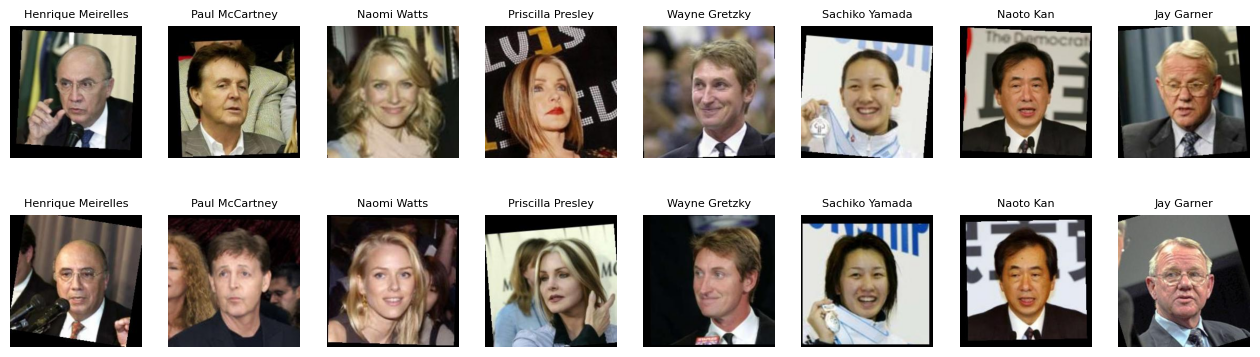

size: (250, 250) mode: RGB


In [5]:
random.seed(42)
people = counts[counts >= 2].index.tolist()
picked = random.sample(people, 8)

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for col, name in enumerate(picked):
    photos = sorted((FACES_DIR / name).glob("*.jpg"))[:2]
    for row, photo in enumerate(photos):
        axes[row, col].imshow(Image.open(photo))
        axes[row, col].set_title(name.replace("_", " "), fontsize=8)
        axes[row, col].axis("off")
plt.show()

sample = Image.open(next(FACES_DIR.glob("*/*.jpg")))
print("size:", sample.size, "mode:", sample.mode)

## 4. EDA: Kaggle Human Faces (strangers set)

This set has no identities. We use it for dashboard visuals, look-alikes and extra strangers when testing false accepts. We measure image sizes, colour modes and brightness on a random sample of 1000.

100%|██████████| 1.82G/1.82G [00:15<00:00, 127MB/s]

Extracting files...


Total images: 7219
             width       height   brightness
count  1000.000000  1000.000000  1000.000000
mean    851.819000  1025.547000   119.719260
std     683.762189   726.456896    37.672541
min     199.000000   236.000000    35.975441
25%     600.000000   600.000000    91.924201
50%     626.000000   819.000000   118.724992
75%     800.000000  1104.000000   145.017335
max    8675.000000  5760.000000   227.874508
mode
RGB     964
L        22
RGBA     12
P         2
Name: count, dtype: int64


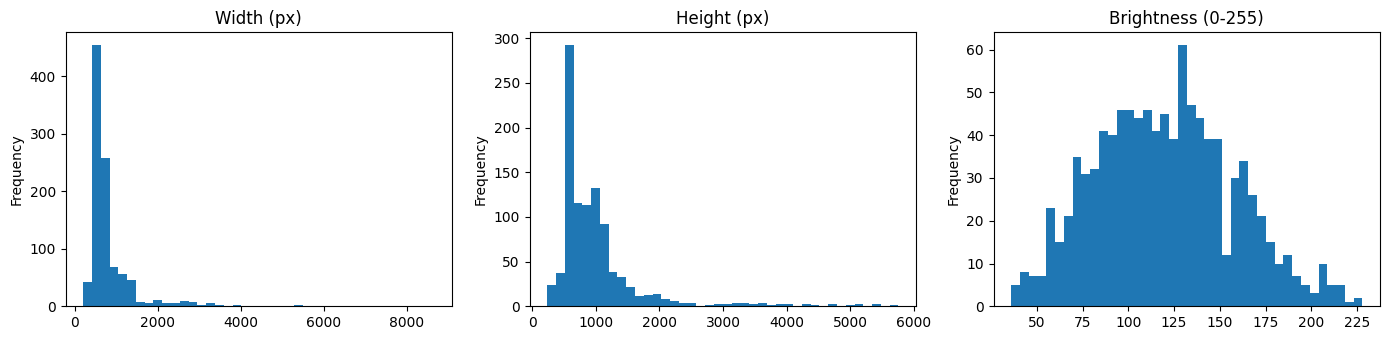

In [6]:
if IN_COLAB:
    HUMANS_DIR = Path(kagglehub.dataset_download("ashwingupta3012/human-faces")) / "Humans"
else:
    HUMANS_DIR = Path("../data/human-faces/Humans")

files = [p for p in HUMANS_DIR.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
print("Total images:", len(files))

rows = []
for f in random.sample(files, 1000):
    with Image.open(f) as im:
        gray = np.asarray(im.convert("L"))
        rows.append({"width": im.width, "height": im.height,
                     "mode": im.mode, "brightness": gray.mean()})
stats = pd.DataFrame(rows)

print(stats.describe())
print(stats["mode"].value_counts())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
stats["width"].plot(kind="hist", bins=40, ax=axes[0], title="Width (px)")
stats["height"].plot(kind="hist", bins=40, ax=axes[1], title="Height (px)")
stats["brightness"].plot(kind="hist", bins=40, ax=axes[2], title="Brightness (0-255)")
plt.tight_layout()
plt.show()

## 5. Train / test split by person

We cap photos per person (LFW is very lopsided), remove LFW's official test people so the official benchmark stays untouched, then split the remaining people 80/20. Splitting by person means test people are never seen in training.

In [7]:
MAX_PHOTOS_PER_PERSON = 20
TEST_FRACTION = 0.2
VAL_FRACTION = 0.1
SEED = 42

rng = random.Random(SEED)
official_test_people = set(pd.read_csv(LFW_ROOT / "peopleDevTest.csv")["name"])

index = {}
for person_dir in sorted(FACES_DIR.iterdir()):
    if person_dir.name in official_test_people:
        continue
    photos = sorted(person_dir.glob("*.jpg"))
    if len(photos) >= 2:
        keep = rng.sample(photos, min(len(photos), MAX_PHOTOS_PER_PERSON))
        index[person_dir.name] = [str(p) for p in sorted(keep)]

names = sorted(index)
rng.shuffle(names)
n_test = int(len(names) * TEST_FRACTION)
n_val = int(len(names) * VAL_FRACTION)
test_index = {n: index[n] for n in names[:n_test]}
val_index = {n: index[n] for n in names[n_test : n_test + n_val]}
train_index = {n: index[n] for n in names[n_test + n_val :]}

assert not set(train_index) & set(val_index)
assert not set(train_index) & set(test_index)
assert not set(val_index) & set(test_index)
for label, idx in [("train", train_index), ("val", val_index), ("test", test_index)]:
    print(f"{label:5s} people: {len(idx):4d}  photos: {sum(map(len, idx.values()))}")

train people:  830  photos: 3505
val   people:  118  photos: 530
test  people:  236  photos: 1186


## 6. Evaluation pairs

Two benchmarks: pairs we build from our held-out people, and LFW's official `DevTest` pairs (people never used in training).

In [8]:
test_pairs = build_pairs(test_index, n_pairs=2000, seed=SEED)
val_pairs = build_pairs(val_index, n_pairs=1000, seed=SEED)


def lfw_photo(name, number):
    return str(FACES_DIR / name / f"{name}_{number:04d}.jpg")


match = pd.read_csv(LFW_ROOT / "matchpairsDevTest.csv")
mismatch = pd.read_csv(LFW_ROOT / "mismatchpairsDevTest.csv")

official_pairs = [
    (lfw_photo(n, a), lfw_photo(n, b), 1)
    for n, a, b in zip(match.iloc[:, 0], match.iloc[:, 1], match.iloc[:, 2])
] + [
    (lfw_photo(n1, a), lfw_photo(n2, b), 0)
    for n1, a, n2, b in zip(
        mismatch.iloc[:, 0], mismatch.iloc[:, 1], mismatch.iloc[:, 2], mismatch.iloc[:, 3]
    )
]

assert all(Path(a).exists() and Path(b).exists() for a, b, _ in official_pairs)
print("val pairs:", len(val_pairs), "| own test pairs:", len(test_pairs),
      "| official pairs:", len(official_pairs))

val pairs: 1000 | own test pairs: 2000 | official pairs: 1000


## 7. Does the app's face detector work on LFW?

The app feeds the model tight face crops from `detect_and_crop`. Training on loose full photos would be a mismatch, so we check how often the detector finds exactly one face in training photos and what the crops look like.

exactly one face found: 275/300 (92%)
median crop size (height, width): [162. 162.]


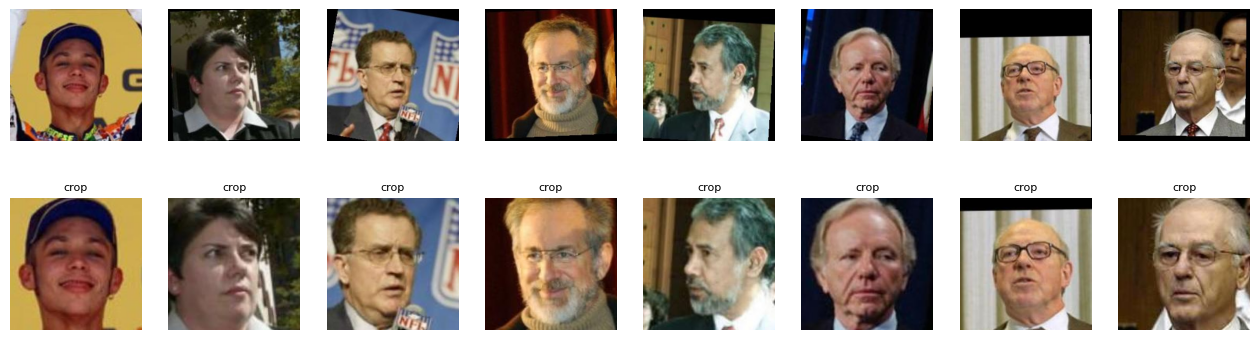

In [9]:
all_train_photos = [p for photos in train_index.values() for p in photos]
sample_paths = random.Random(SEED).sample(all_train_photos, 300)

found, sizes = 0, []
for path in sample_paths:
    img = np.asarray(Image.open(path).convert("RGB"))
    crop = detect_and_crop(img)
    if crop is not None:
        found += 1
        sizes.append(crop.shape[:2])

print(f"exactly one face found: {found}/300 ({found / 300:.0%})")
print("median crop size (height, width):", np.median(sizes, axis=0))

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for col, path in enumerate(sample_paths[:8]):
    img = np.asarray(Image.open(path).convert("RGB"))
    crop = detect_and_crop(img)
    axes[0, col].imshow(img)
    axes[1, col].imshow(crop if crop is not None else np.zeros((10, 10, 3), np.uint8))
    axes[1, col].set_title("crop" if crop is not None else "NO FACE", fontsize=8)
    axes[0, col].axis("off")
    axes[1, col].axis("off")
plt.show()

## 8. Cache the preprocessed faces

Face detection is slow, so we run it once over every photo we need (train, validation, test and the official pairs) and keep the 160x160 `uint8` crops in one array. Photos where detection fails fall back to a centre crop (only for training data; the app rejects such photos instead).

In [10]:
CACHE_DIR = Path("../data/cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)


def load_face(path):
    img = np.asarray(Image.open(path).convert("RGB"))
    face = detect_and_crop(img)
    if face is None:
        face = center_crop(img)
    return resize_face(face)


photo_paths = sorted(
    {p for idx in (train_index, val_index, test_index) for photos in idx.values() for p in photos}
    | {p for a, b, _ in official_pairs for p in (a, b)}
)
faces = np.stack([load_face(p) for p in photo_paths])
row_of = {p: i for i, p in enumerate(photo_paths)}

np.save(CACHE_DIR / "faces.npy", faces)
print(faces.shape, faces.dtype, f"{faces.nbytes / 1e6:.0f} MB")

(6770, 160, 160, 3) uint8 520 MB


## 9. Training arrays

Turn the cached faces into the arrays the trainer needs: training photos with one integer label per person, and the validation photos with their pair rows.

In [11]:
train_names = sorted(train_index)
label_of = {name: i for i, name in enumerate(train_names)}
train_rows = [row_of[p] for n in train_names for p in train_index[n]]
y_train = np.array([label_of[n] for n in train_names for _ in train_index[n]])
x_train = faces[train_rows]

val_paths = sorted({p for photos in val_index.values() for p in photos})
val_row = {p: i for i, p in enumerate(val_paths)}
x_val = faces[[row_of[p] for p in val_paths]]
val_data = (
    x_val,
    np.array([val_row[a] for a, _, _ in val_pairs]),
    np.array([val_row[b] for _, b, _ in val_pairs]),
    np.array([label for _, _, label in val_pairs]),
)
print("train:", x_train.shape, "identities:", len(train_names), "| val:", x_val.shape)

train: (3505, 160, 160, 3) identities: 830 | val: (530, 160, 160, 3)


### Finding from attempt 1: a plain softmax head underfits

Our first attempt trained the embedding through a plain `Dense` softmax classifier on unit-length embeddings. Result (best run chosen by validation AUC, test pairs / LFW official pairs):

| Run | Test AUC | Official AUC |
|---|---|---|
| 1 baseline | 0.862 | 0.881 |
| 2 + augmentation | 0.814 | 0.829 |
| 3 + regularisation | 0.791 | 0.823 |
| 4 + fine-tuning | 0.811 | 0.841 |

Every technique made things *worse*, and the training loss never fell below about 4.7 (a random guess over 830 people scores 6.7). That is **underfitting**: with unit-length embeddings the plain classifier's scores are capped, so the loss has a floor and the model cannot fit the training people. Regularisation and augmentation make a model that cannot fit even harder to fit, so they hurt.

**Fix (attempt 2):** a scaled cosine-margin head. Scores are `30 * (cosine - 0.25)` for the true person, which lifts the cap and forces same-person embeddings to be clearly closer than anyone else's. Label smoothing is dropped (the margin already plays that role), and fine-tuning now unfreezes 100 backbone layers at a learning rate of 1e-4.

### Finding from attempt 2: the margin head fixes underfitting; fine-tuning is the big lever

With the cosine-margin head (test pairs / LFW official pairs):

| Run | Test AUC | Official AUC |
|---|---|---|
| 1 baseline | 0.844 | 0.823 |
| 2 + augmentation | 0.827 | 0.843 |
| 3 + regularisation | 0.829 | 0.852 |
| 4 + fine-tuning | **0.886** | **0.886** |

The baseline now fits its training people (loss about 0.4) and then overfits (validation AUC peaks at epoch 3 and declines), so regularisation finally has a job. Fine-tuning the backbone gives the largest gain, and run 4's loss and validation AUC were **still improving when early stopping ended it**.

**Attempt 3 (below):** a longer fine-tune: the whole backbone unfrozen (BatchNorm stays frozen), up to 60 epochs, cosine learning-rate decay and patience 10.

### Finding from attempt 3: a longer fine-tune does not help; the recipe is exhausted

Attempt 3 unfroze the whole backbone (BatchNorm stays frozen) for up to 60 epochs with cosine learning-rate decay and patience 10. It ran 47 epochs in total (test pairs / LFW official pairs):

| Run | Test AUC | Official AUC |
|---|---|---|
| 1 baseline | 0.844 | 0.823 |
| 2 + augmentation | 0.827 | 0.843 |
| 3 + regularisation | 0.829 | 0.852 |
| 4 + fine-tuning (long) | **0.887** | **0.888** |

That is no better than attempt 2's 0.886 / 0.886. The training loss kept falling (to about 3.3), but validation AUC stayed flat around 0.88 to 0.90: the model is now **memorising the training people** rather than learning faces that generalise. More epochs will not help; the limit is the ImageNet-pretrained backbone and only 3,505 training photos.

**What this means for logging in.** The login threshold is chosen on the validation pairs for about 2% of different-person pairs accepted (0.494). Measured the way the app is used, over 66 held-out people from LFW's official test set (3-photo enrollment, then one new photo of the same person, plus 5 strangers each):

| | Result |
|---|---|
| Right person accepted on the first try | 67% |
| Strangers accepted | 3.9% |
| Right person accepted if we allow 5% strangers | 77% |

Further gains need a stronger starting point (a face-pretrained backbone) or many more identities.

## 10. Experiments: what does each technique buy?

Four cumulative runs: each adds techniques on top of the previous run. Validation is by verification AUC on held-out people (a classifier can't be scored on people it never saw). The classifier used for training is a **scaled cosine-margin head** (CosFace style). **Run this section on a GPU runtime in Colab.**

In [12]:
EPOCHS = 30
REG = dict(dropout=0.3, l2=1e-4, early_stopping=True)
RUNS = [
    RunConfig("1 baseline"),
    RunConfig("2 + augmentation", augment=True),
    RunConfig("3 + regularisation", augment=True, **REG),
    RunConfig(
        "4 + fine-tuning", augment=True, fine_tune=True, unfreeze_layers=10_000,
        fine_tune_epochs=60, patience=10, cosine_decay=True, **REG,
    ),
]

results = {}
for config in RUNS:
    embedding, history = train(
        config, (x_train, y_train), val_data, n_classes=len(train_names), epochs=EPOCHS
    )
    results[config.name] = (embedding, history)
    print(f"{config.name:22s} best val AUC: {max(history['val_auc']):.4f}  "
          f"epochs run: {len(history['loss'])}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
1 baseline             best val AUC: 0.8665  epochs run: 30
2 + augmentation       best val AUC: 0.8331  epochs run: 30
3 + regularisation     best val AUC: 0.8363  epochs run: 17
4 + fine-tuning        best val AUC: 0.8986  epochs run: 47


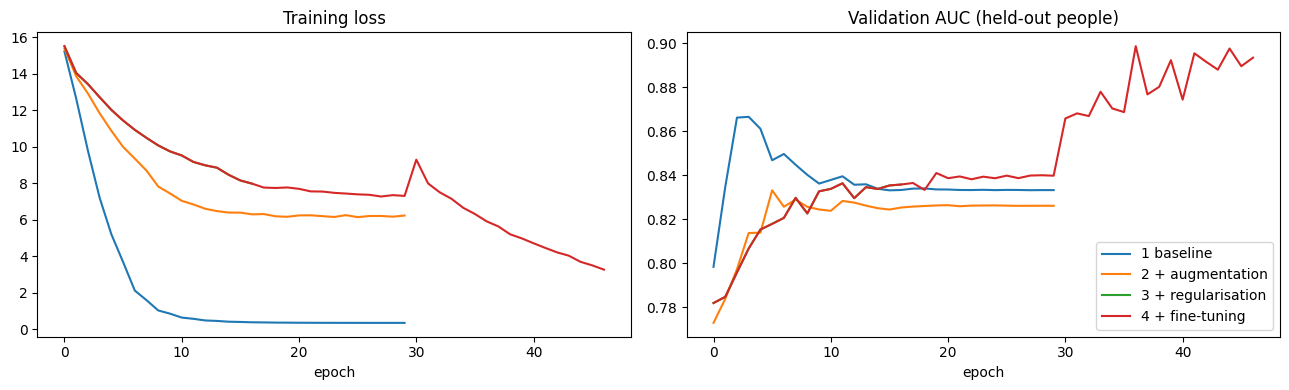

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, (_, history) in results.items():
    axes[0].plot(history["loss"], label=name)
    axes[1].plot(history["val_auc"], label=name)
axes[0].set(title="Training loss", xlabel="epoch")
axes[1].set(title="Validation AUC (held-out people)", xlabel="epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

## 11. Evaluation

For each run: pick the decision threshold on the **validation** pairs (equal error rate), then report that threshold's accuracy, precision, recall, F1 and AUC on our own held-out test pairs and on LFW's official pairs.

In [14]:
embeddings_of = {}


def pair_arrays(pairs):
    return (
        np.array([row_of[a] for a, _, _ in pairs]),
        np.array([row_of[b] for _, b, _ in pairs]),
        np.array([label for _, _, label in pairs]),
    )


def evaluate_run(model):
    emb = embed_faces(model, faces)
    out = {}
    val_rows_a, val_rows_b, val_labels = pair_arrays(val_pairs)
    val_metrics = evaluate_pairs(pair_scores(emb, val_rows_a, val_rows_b), val_labels)
    out["val"] = val_metrics
    for split, pairs in [("test", test_pairs), ("official", official_pairs)]:
        rows_a, rows_b, labels = pair_arrays(pairs)
        out[split] = evaluate_pairs(
            pair_scores(emb, rows_a, rows_b), labels, threshold=val_metrics["threshold"]
        )
    return out


evaluations = {name: evaluate_run(model) for name, (model, _) in results.items()}

keys = ["accuracy", "precision", "recall", "f1", "auc", "far", "frr"]
table = pd.DataFrame(
    {
        (split, key): [evaluations[name][split][key] for name in evaluations]
        for split in ["test", "official"]
        for key in keys
    },
    index=list(evaluations),
).round(3)
table

test                                               \
                   accuracy precision recall     f1    auc    far    frr   
1 baseline            0.759     0.768  0.743  0.755  0.844  0.225  0.257   
2 + augmentation      0.759     0.783  0.717  0.748  0.827  0.199  0.283   
3 + regularisation    0.750     0.771  0.712  0.740  0.829  0.212  0.288   
4 + fine-tuning       0.808     0.798  0.825  0.811  0.887  0.209  0.175   

                   official                                               
                   accuracy precision recall     f1    auc    far    frr  
1 baseline            0.757     0.771  0.732  0.751  0.823  0.218  0.268  
2 + augmentation      0.760     0.770  0.742  0.756  0.843  0.222  0.258  
3 + regularisation    0.778     0.788  0.760  0.774  0.852  0.204  0.240  
4 + fine-tuning       0.806     0.802  0.812  0.807  0.888  0.200  0.188

## 12. Save the best model

The best run by validation AUC is saved with its threshold and metrics (including ROC curves) for the app and dashboard.

In [15]:
best_name = max(results, key=lambda n: max(results[n][1]["val_auc"]))
best_model, best_history = results[best_name]
print("best run:", best_name)

MODELS_DIR = Path("../models")
MODELS_DIR.mkdir(exist_ok=True)
best_model.save(MODELS_DIR / "faceunlock_v1.keras")
report = {
    "run": best_name,
    "threshold": evaluations[best_name]["val"]["threshold"],
    "train_history": best_history,
    "metrics": {split: evaluations[best_name][split] for split in ["val", "test", "official"]},
    "experiments": {
        name: {split: {k: ev[split][k] for k in keys} for split in ["test", "official"]}
        for name, ev in evaluations.items()
    },
}
(MODELS_DIR / "metrics_v1.json").write_text(json.dumps(report, indent=2))

if IN_COLAB:
    from google.colab import files
    files.download(str(MODELS_DIR / "faceunlock_v1.keras"))
    files.download(str(MODELS_DIR / "metrics_v1.json"))

best run: 4 + fine-tuning


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>